# **PROJECT 6:POKEMON IMAGE CLASSIFICATION**

In [31]:
import os

import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

In [32]:
#The Data
classes = ['Pikachu', 'Charmander', 'Bulbasaur']
train_data = []
train_labels = []

for category in classes:
    folder = f'Pokemon Dataset/Train/{category}'
    print(f"Loading {category}...")
    for img_name in os.listdir(folder):
        img_path = f'{folder}/{img_name}'
        img = image.load_img(img_path, target_size=(100, 100))
        train_data.append(image.img_to_array(img))
        train_labels.append(category)

Loading Pikachu...
Loading Charmander...


C:\Users\vaibh\OneDrive\Documents\COMPUTER VISION\.venv\.venv\lib\site-packages\PIL\Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Loading Bulbasaur...


In [33]:
#Data Preprocessing
import numpy as np
from tensorflow.keras.utils import to_categorical
from sklearn.utils import shuffle

# 1. FIX: NORMALIZE DATA
# Ensure data is float and normalized to 0-1 range
train_data = np.array(train_data).astype('float32')
if np.max(train_data) > 1.0:
    print("Normalizing data (dividing by 255)...")
    train_data = train_data / 255.0

# 2. FIX: LABELS
# We reconstruct the labels to ensure they are raw integers first
# (This prevents the 'Double Encoding' bug)
cat2lab = {'Pikachu': 0, 'Charmander': 1, 'Bulbasaur': 2}
lab2cat = {0:'Pikachu', 1:'Charmander', 2:'Bulbasaur'}
clean_labels = []

for label in train_labels:
    # If it's a string, convert it to int
    if isinstance(label, str):
        clean_labels.append(cat2lab[label])
    # If it's an array/list (already encoded), try to revert or handle it
    # But for safety, let's assume if it's not a string, it might be an int
    elif isinstance(label, (int, np.integer)):
         clean_labels.append(int(label))
    # If it is already one-hot (array), decode it back to int
    elif isinstance(label, (list, np.ndarray)) and len(label) == 3:
        clean_labels.append(np.argmax(label))

train_labels = np.array(clean_labels)

train_data, train_labels = shuffle(train_data, train_labels, random_state=42)
# 4. APPLY ONE-HOT ENCODING
# Only apply if labels are not already (N, 3)
if train_labels.ndim == 1:
    print(f"Applying One-Hot Encoding to {len(train_labels)} labels...")
    train_labels = to_categorical(train_labels, num_classes=3)

# Flatten images from (304, 100, 100, 3) to (304, 30000)
if train_data.ndim > 2:
    print("Flattening image data...")
    train_data = train_data.reshape(len(train_data), -1)

print("\n--- SUCCESS: DATA IS READY ---")
print("Data Shape:   ", train_data.shape)   # MUST BE: (304, 30000)
print("Labels Shape: ", train_labels.shape) # MUST BE: (304, 3)

Normalizing data (dividing by 255)...
Applying One-Hot Encoding to 304 labels...
Flattening image data...

--- SUCCESS: DATA IS READY ---
Data Shape:    (304, 30000)
Labels Shape:  (304, 3)


In [34]:
from keras.utils import to_categorical


if train_labels.ndim == 1:
    print("Encoding labels to One-Hot...")
    train_labels = to_categorical(train_labels, num_classes=3)
else:
    print("✅ Safety Check: Labels are already encoded. Skipping to avoid crash.")

print(f"Current Labels Shape: {train_labels.shape}")

✅ Safety Check: Labels are already encoded. Skipping to avoid crash.
Current Labels Shape: (304, 3)


In [35]:
train_labels.shape

(304, 3)

In [36]:
train_labels[:5]

array([[0., 1., 0.],
       [0., 1., 0.],
       [0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

In [37]:
#Model Architecture
from keras.models import Sequential
from keras.layers import Dense

# Get the number of features (should be 30000)
feats = train_data.shape[1]

model = Sequential()
# Input shape must match 'feats'
model.add(Dense(512, activation='relu', input_shape=(feats,)))
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(3, activation='softmax')) # Output 3 for 3 Pokemon classes

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

#Model Training
model.fit(train_data, train_labels, epochs=50, batch_size=32)

C:\Users\vaibh\OneDrive\Documents\COMPUTER VISION\.venv\.venv\lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 512)            │    15,360,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,533,187 (59.25 MB)

 Trainable params: 15,533,187 (59.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.3487 - loss: 7.2415
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.5263 - loss: 2.2591
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.6086 - loss: 1.6172
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.6842 - loss: 0.9431
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.7072 - loss: 1.0053
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.8059 - loss: 0.5140
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.8125 - loss: 0.4951
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.8289 - loss: 0.4100
Epoch 9/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.9375 - loss: 0.1777
Epoch 10/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9474 - loss: 0.1485
Epoch 11/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.9375 - loss: 0.1692
Epoch 12/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy:

In [38]:
#Test Data
test_data=[]
test_labels=[]
for category in classes:
    folder = f'Pokemon Dataset/Test/{category}'
    print(f"Loading {category}...")
    for img_name in os.listdir(folder):
        img_path = f'{folder}/{img_name}'
        img = image.load_img(img_path, target_size=(100, 100))
        test_data.append(image.img_to_array(img))
        test_labels.append(category)


Loading Pikachu...
Loading Charmander...
Loading Bulbasaur...


In [39]:
len(test_data)

123

In [40]:
test_data=np.array(test_data)
test_labels = np.array(test_labels)

In [41]:
test_data.shape

(123, 100, 100, 3)

In [42]:
test_labels

array(['Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu',
       'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu',
       'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu',
       'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu',
       'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu',
       'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu',
       'Pikachu', 'Pikachu', 'Pikachu', 'Pikachu', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charmander',
       'Charmander', 'Charmander', 'Charmander', 'Charma

In [43]:
test_labels=np.array([cat2lab[label] for label in test_labels])
test_labels=to_categorical(test_labels)

In [44]:
test_labels.shape

(123, 3)

In [45]:
test_data=test_data.reshape(len(test_data), 30000)
test_data.shape

(123, 30000)

In [46]:
model.evaluate(test_data, test_labels)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9756 - loss: 31.5521


[31.552127838134766, 0.9756097793579102]

In [47]:
pred=model.predict(test_data).argmax(axis=1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [48]:
pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 2])

In [49]:
#Prediction
test_img='Pokemon Dataset/Test/Bulbasaur/1110.jpg'

img=image.load_img(test_img,target_size=(100,100))
test_img=image.img_to_array(img)
test_img.shape

(100, 100, 3)

In [50]:
import matplotlib.pyplot as plt

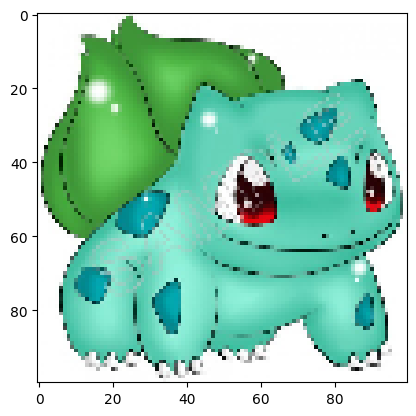

In [51]:
plt.imshow(test_img.astype('int'));

In [52]:
test_img=test_img.reshape(1, 30000)
test_img.shape

(1, 30000)

In [54]:
pred=lab2cat[model.predict(test_img).argmax()]
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


'Bulbasaur'

In [59]:
test_img1='Pokemon Dataset/Test/Charmander/2215.jpg'

img=image.load_img(test_img1,target_size=(100,100))
test_img1=image.img_to_array(img)
test_img1.shape

(100, 100, 3)

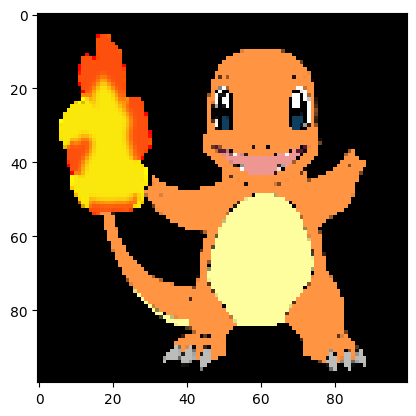

In [61]:
plt.imshow(test_img1.astype('int'))

In [62]:
test_img1=test_img1.reshape(1, 30000)
test_img1.shape

(1, 30000)

In [65]:
pred=lab2cat[model.predict(test_img1).argmax()]
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


'Charmander'